# Etapa 2 - Análise exploratória e processamento de dados com Pandas
## SIASUS: produção ambulatorial dos estabelecimentos de Ijuí

## 1. Fonte de dados: Estratégia A (VIEW)

A VIEW deve realiza os relacionamentos com as tabelas descritivas e reduzir a base de dados **apenas para os dados do Município de Ijuí** (`pa_ufmun = '431020'`). 

### Instalação das bibliotecas necessárias

Execute **uma vez, se ainda não estiverem instaladas**, em uma célula de código do Jupyter:

```python
%pip install pandas mysql-connector-python matplotlib seaborn
```

- `pandas`: preparação, agrupamento e análise dos dados.
- `mysql-connector-python`: conexão com o MySQL.
- `matplotlib`: construção e personalização dos gráficos.
- `seaborn`: visualizações estatísticas sobre os DataFrames.

Após instalar, reinicie o kernel se necessário. Execute as células da Etapa 2 antes das visualizações.


## 2. Conexão com o MySQL

Podemos manter a mesma função de conexão utilizada na Aula 11. Executar e informar as credenciais do MySQL quando solicitado.

In [1]:
# conexao.py
from getpass import getpass
from mysql.connector import connect, Error

def usar_conexao(acao):
    try:
        with connect(
            host="localhost",               # Endereço do servidor MySQL (localhost)
            user=input("Usuário: "),        # Solicita ao usuário o nome de login
            password=getpass("Senha: ")     # Solicita a senha de forma oculta
        ) as connection:
            print("Conexão estabelecida:", connection)
            return acao(connection)
    except Error as e:
        print("Ocorreu um erro ao conectar com o BD: ", e)

## 3. Carregar os dados da VIEW para um DataFrame

Todos os exemplos seguintes utilizam DataFrames derivados de `tabela`. DataFrame é uma estrutura de dados bidimensional que organiza as informações em uma tabela de linhas e colunas, semelhante a uma planilha do Excel ou a uma tabela de banco de dados SQL.

**Requisito de infraestrutura:** `fetchall()` carrega os registros na memória antes de construir o DataFrame. 

In [2]:
import pandas as pd

# Consulta SQL única para recuperar todas as colunas e linhas da VIEW.
def carregar_dados(connection):
    with connection.cursor() as cursor:
        cursor.execute("SELECT * FROM dbsia.pa_ijui")
        return pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)

tabela = usar_conexao(carregar_dados)

display(tabela.head(10))

Usuário:  root
Senha:  ········


Conexão estabelecida: <mysql.connector.connection_cext.CMySQLConnection object at 0x10c8e0940>


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,041,0000,CID NAO INFORMADO,IJUI,None,1,1,6.30,6.30
1,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,065,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
2,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,059,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
3,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,068,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
4,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,035,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
5,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,052,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
6,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,068,0000,CID NAO INFORMADO,IJUI,None,2,2,12.60,12.60
7,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA MEDICA EM ATENCAO PRIMARIA,Medico clinico,0,032,0000,CID NAO INFORMADO,IJUI,None,3,3,0.00,0.00
8,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,072,0000,CID NAO INFORMADO,IJUI,None,1,1,6.30,6.30
9,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA MEDICA EM ATENCAO PRIMARIA,Medico clinico,0,024,0000,CID NAO INFORMADO,IJUI,None,2,2,0.00,0.00


## 4. Exploração inicial - dimensão

**Perguntas:** quantos registros e variáveis existem? 

In [3]:
print("Quantidade de linhas:", len(tabela))
print("Colunas disponíveis:", list(tabela.columns))
display(tabela.head(5))

Quantidade de linhas: 70377
Colunas disponíveis: ['Ano', 'Mes', 'AnoBimestre', 'AnoTrimestre', 'Estabelecimento', 'Procedimento', 'Ocupacao', 'pa_sexo', 'pa_idade', 'pa_cidpri', 'Diagnostico', 'MunicipioEstabelecimento', 'MunicipioPaciente', 'pa_qtdpro', 'pa_qtdapr', 'pa_valpro', 'pa_valapr']


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,041,0000,CID NAO INFORMADO,IJUI,None,1,1,6.30,6.30
1,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,065,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
2,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,059,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
3,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,068,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
4,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,035,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90


## 5. Preparação dos tipos de dados

Os campos de quantidade e valor precisam ser numéricos para operações matemáticas. 

In [4]:
colunas_numericas = ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]
for coluna in colunas_numericas:
    tabela[coluna] = pd.to_numeric(tabela[coluna])

display(tabela[colunas_numericas].head())

,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,1,1,6.3,6.3
1,3,3,18.9,18.9
2,3,3,18.9,18.9
3,3,3,18.9,18.9
4,3,3,18.9,18.9


## 6. Estatísticas descritivas e distribuições de frequência

`describe()` apresenta contagem não nula, média, desvio-padrão, quartis, mínimo e máximo. A distribuição de frequências de variáveis pode ser obtida com `value_counts()`. 

In [5]:
display(tabela[colunas_numericas].describe())
print("Estabelecimentos mais frequentes por número de registros:")
display(tabela["Estabelecimento"].value_counts().head(10))
print("Distribuição dos códigos de sexo presentes:")
display(tabela["pa_sexo"].value_counts())

,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
count,70377.000000,70377.000000,70377.000000,70377.000000
mean,7.464015,5.667050,98.820903,97.194167
std,54.591756,49.411909,634.935089,636.061808
min,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.850000,0.000000
50%,1.000000,1.000000,6.300000,3.370000
75%,1.000000,1.000000,17.670000,10.900000
max,6284.000000,5337.000000,60741.370000,60741.370000


Estabelecimentos mais frequentes por número de registros:


Estabelecimento
HOSPITAL DE CLINICAS IJUI                                24265
HOSPITAL BOM PASTOR IJUI                                 19162
17 COORDENADORIA REGIONAL DE SAUDE                        7573
CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE             4326
APAE IJUI                                                 3183
CER III UNIR                                              2838
CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO     2825
CENTRO AUDITIVO PROAUDI                                   2354
CISA                                                      1766
CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA               1048
Name: count, dtype: int64

Distribuição dos códigos de sexo presentes:


pa_sexo
F    34730
M    32857
0     2790
Name: count, dtype: int64

---
# Etapa 3 - Visualização de dados e interpretação dos resultados

**Objetivo:** transformar as tabelas produzidas com Pandas em representações visuais que permitam comparar períodos, estabelecimentos, procedimentos, municípios e indicadores financeiros.

**Pré-requisito:** os dados já devem ter sido carregados na Etapa 2. 

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define o estilo visual dos gráficos.
sns.set_theme(style="darkgrid")

## 7. Avaliação da qualidade dos dados

Verificar a quantidade de **NULL / NaN**. 

In [7]:
# Nulos/NaN, por coluna.
nulos = tabela.isna().sum().sort_values(ascending=False)
display(nulos.to_frame("Nulos"))

,Nulos
MunicipioPaciente,2790
Diagnostico,9
Ano,0
pa_cidpri,0
pa_valpro,0
pa_qtdapr,0
pa_qtdpro,0
MunicipioEstabelecimento,0
pa_idade,0
Mes,0


## Visualização da qualidade dos dados - barras horizontais

**Pergunta:** em quais atributos existem mais registros ausentes? O gráfico de barras horizontais permite comparar frequências por coluna.

**Interpretação:** um campo sem informação não é automaticamente um erro. Os registros do SIASUS apresentam diferentes regras de preenchimento, conforme o instrumento de registro. 


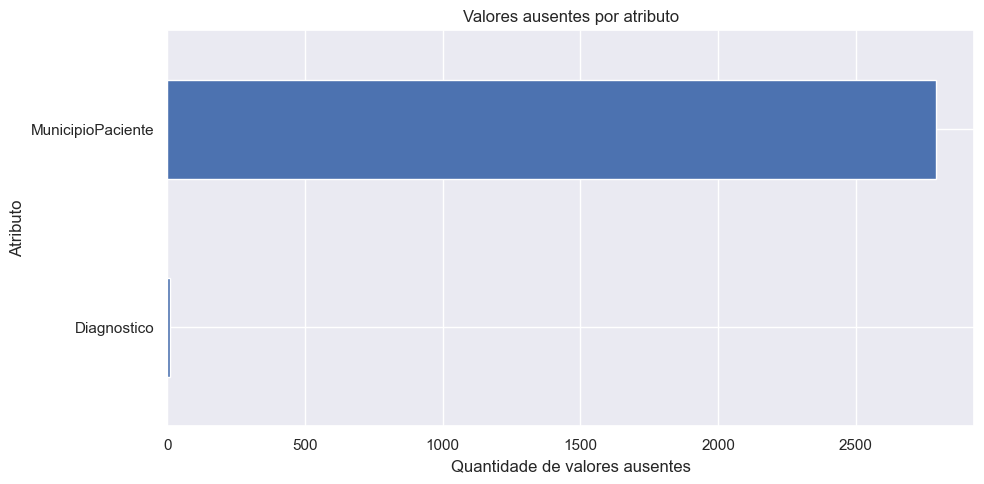

In [8]:
# Seleciona somente as colunas que possuem valores ausentes.
dados = nulos[nulos > 0].sort_values()

# Cria o gráfico de barras horizontais.
dados.plot(
    kind="barh", 
    figsize=(10, 5)
)

plt.title("Valores ausentes por atributo")
plt.xlabel("Quantidade de valores ausentes")
plt.ylabel("Atributo")

plt.tight_layout()
plt.show()

## 8. Indicadores gerais da produção ambulatorial

Distinga **número de registros**, **quantidades de procedimentos apresentadas/aprovadas** e **valores apresentados/aprovados**. 

In [9]:
geral = pd.DataFrame([{
    "Registros": len(tabela),
    "QuantidadeApresentada": tabela["pa_qtdpro"].sum(),
    "QuantidadeAprovada": tabela["pa_qtdapr"].sum(),
    "ValorApresentado": tabela["pa_valpro"].sum(),
    "ValorAprovado": tabela["pa_valapr"].sum()
}])
display(geral)

,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,70377,525295,398830,6954718.7,6840233.87



## Visualização dos indicadores gerais da produção ambulatorial — gráficos de barras

**Pergunta:** qual é a quantidade total de procedimentos apresentados e aprovados pelo SUS? Qual é a diferença entre os valores financeiros apresentados e aprovados?

**Interpretação:** os gráficos permitem comparar a produção ambulatorial apresentada com a aprovada, tanto em quantidade de procedimentos quanto em valores financeiros. 

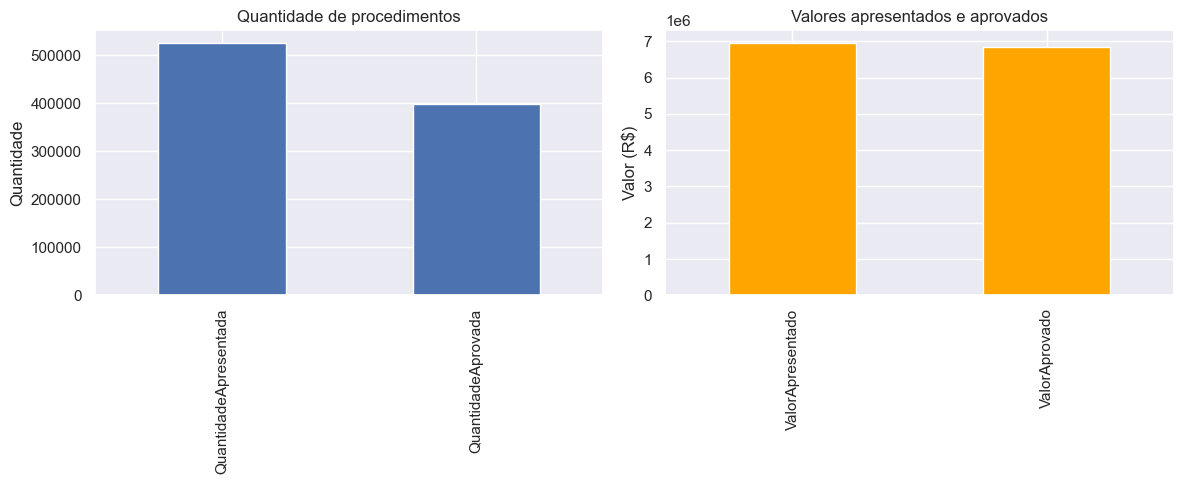

In [10]:
# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: quantidade de procedimentos.
geral[["QuantidadeApresentada", "QuantidadeAprovada"]].T.plot(
    kind="bar", 
    ax=axes[0], 
    legend=False
)
axes[0].set_title("Quantidade de procedimentos")
axes[0].set_ylabel("Quantidade")

# Gráfico 2: valores financeiros.
geral[["ValorApresentado", "ValorAprovado"]].T.plot(
    kind="bar",
    color=["orange", "green"], 
    ax=axes[1], 
    legend=False
)
axes[1].set_title("Valores apresentados e aprovados")
axes[1].set_ylabel("Valor (R$)")

plt.tight_layout()
plt.show()

## 9. Análise temporal - mês

Podemos agrupar **ano + mês**.

In [11]:
mensal = (
    tabela.groupby(["Ano", "Mes"], dropna=False, as_index=False)
    .agg(Registros=("Procedimento", "size"),
         QuantidadeApresentada=("pa_qtdpro", "sum"),
         QuantidadeAprovada=("pa_qtdapr", "sum"),
         ValorApresentado=("pa_valpro", "sum"),
         ValorAprovado=("pa_valapr", "sum"))
    .sort_values(["Ano", "Mes"])
)


print("Produção mensal:")
display(mensal)

Produção mensal:


,Ano,Mes,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,2026,7,70377,525295,398830,6954718.7,6840233.87


## Evolução mensal - gráfico de linhas

**Pergunta:** como evolui a quantidade de procedimentos apresentados e aprovados por mês?

O gráfico de **linhas** é adequado quando o eixo horizontal representa uma sequência temporal ordenada. A tabela vincula `Ano` e `Mes` ao **mês de movimentação (`pa_mvm`)**.

**Cuidado:** se houver apenas dois meses, o gráfico mostra uma comparação pontual; não permite estabelecer tendência de longo prazo.

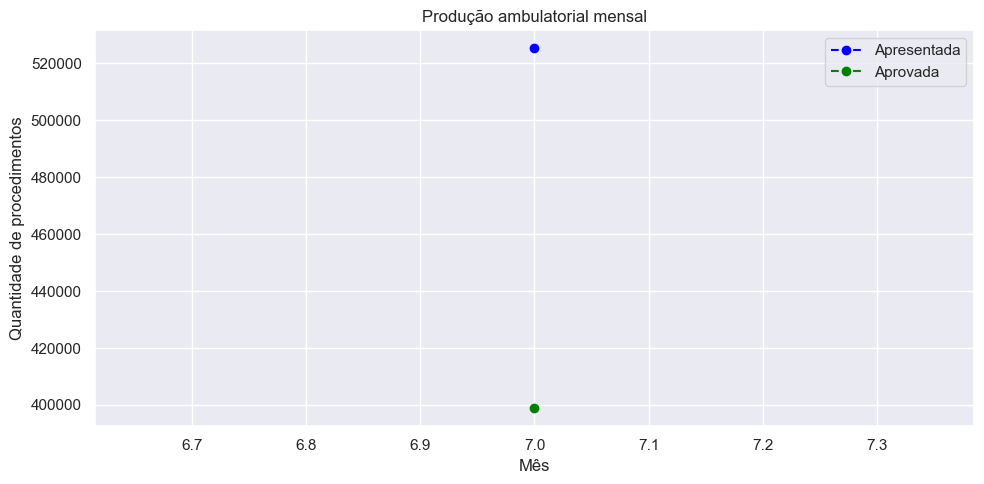

In [12]:
# Cria o gráfico de linhas com os dados calculados na Etapa 2.
mensal.plot(
    x="Mes",
    y=["QuantidadeApresentada", "QuantidadeAprovada"],
    kind="line",
    linestyle="--",
    marker="o",
    color=["blue", "green"],
    figsize=(10, 5)
)

plt.title("Produção ambulatorial mensal")
plt.xlabel("Mês")
plt.ylabel("Quantidade de procedimentos")
plt.legend(["Apresentada", "Aprovada"])
plt.grid(True)

plt.tight_layout()
plt.show()

## Bimestre e trimestre - subplots

**Pergunta:** como a produção se distribui nos bimestres e trimestres?

Aqui os agrupamentos utilizam `AnoBimestre` e `AnoTrimestre` já presentes na tabela.


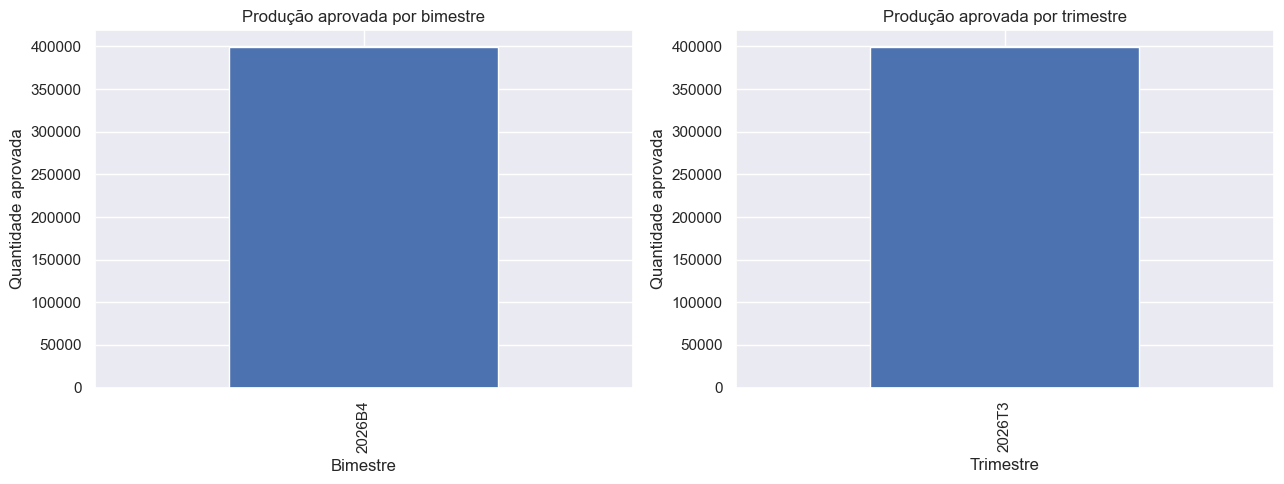

In [13]:
# Agrupa a quantidade aprovada por bimestre e trimestre.
bimestral = tabela.groupby("AnoBimestre")["pa_qtdapr"].sum()
trimestral = tabela.groupby("AnoTrimestre")["pa_qtdapr"].sum()

# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico por bimestre.
bimestral.plot(
    kind="bar", 
    ax=axes[0]
)
axes[0].set_title("Produção aprovada por bimestre")
axes[0].set_xlabel("Bimestre")
axes[0].set_ylabel("Quantidade aprovada")

# Gráfico por trimestre.
trimestral.plot(
    kind="bar", 
    ax=axes[1]
)
axes[1].set_title("Produção aprovada por trimestre")
axes[1].set_xlabel("Trimestre")
axes[1].set_ylabel("Quantidade aprovada")

# Exibe os gráficos.
plt.tight_layout()
plt.show()

## 10. Produção por estabelecimento

`Estabelecimento` já contém a descrição na VIEW. 
- `dropna=False`: inclui nos agrupamentos os registros que possuem valores ausentes (`NaN`) na coluna utilizada para agrupar. Por padrão, o Pandas exclui esses grupos (`dropna=True`).
- `as_index=False`: mantém a coluna utilizada no agrupamento como uma coluna normal do DataFrame, em vez de transformá-la em índice.

In [14]:
estabelecimentos = (
    tabela.groupby("Estabelecimento", dropna=False, as_index=False)
    .agg(Registros=("Procedimento", "size"),
         QuantidadeApresentada=("pa_qtdpro", "sum"),
         QuantidadeAprovada=("pa_qtdapr", "sum"),
         ValorApresentado=("pa_valpro", "sum"),
         ValorAprovado=("pa_valapr", "sum"))
    .sort_values("QuantidadeAprovada", ascending=False)
)

display(estabelecimentos.head(10))

,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,17 COORDENADORIA REGIONAL DE SAUDE,7573,337855,241727,1611247.92,1604964.56
11,HOSPITAL DE CLINICAS IJUI,24265,45902,38131,3566820.68,3444109.81
12,LABORATORIO DE ANALISES CLINICAS UNILAB,300,29720,29720,147391.43,147391.43
8,CISA,1766,30553,24659,217267.85,167357.92
17,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,235,24915,21566,68317.20,65916.54
10,HOSPITAL BOM PASTOR IJUI,19162,19166,10173,353881.87,431744.32
9,HEMOVITA,159,8117,8117,42124.13,42124.13
4,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,4326,8005,5184,4624.20,4624.20
5,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,2825,4215,3447,4002.10,4002.10
3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,1048,3494,3324,9161.82,9161.82


## Visualização da produção por estabelecimento de saúde — barras horizontais

**Pergunta:** quais estabelecimentos apresentam maior quantidade de procedimentos aprovados? Quais possuem as maiores diferenças entre as quantidades apresentadas e aprovadas?

**Interpretação:** os gráficos permitem identificar os estabelecimentos que concentram maior produção ambulatorial e aqueles com maiores diferenças absolutas entre a produção apresentada e a aprovada.

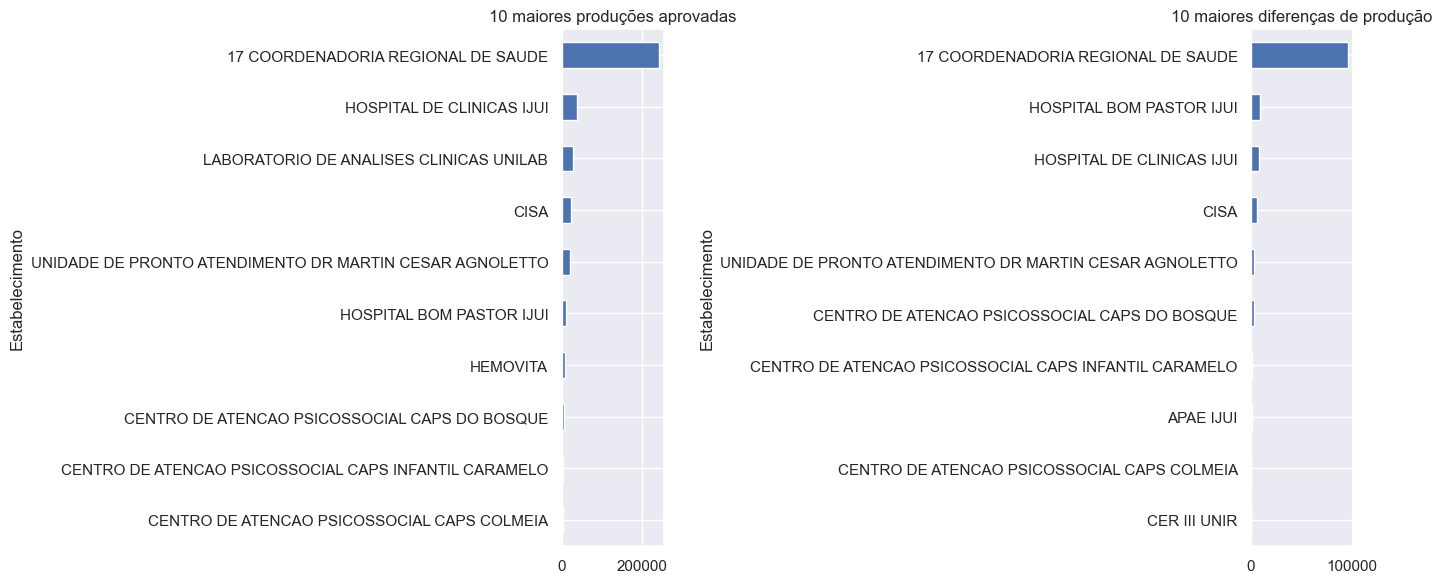

In [15]:
# Calcula a diferença entre quantidades apresentadas e aprovadas.
estabelecimentos["Diferenca"] = (
    estabelecimentos["QuantidadeApresentada"] - estabelecimentos["QuantidadeAprovada"]
)

# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 10 estabelecimentos com maior produção aprovada.
estabelecimentos.nlargest(10, "QuantidadeAprovada").sort_values("QuantidadeAprovada", ascending=True).plot(
    x="Estabelecimento", 
    y="QuantidadeAprovada",
    kind="barh", 
    ax=axes[0], 
    legend=False
)
axes[0].set_title("10 maiores produções aprovadas")

# 10 estabelecimentos com maior diferença.
estabelecimentos.nlargest(10, "Diferenca").sort_values("Diferenca", ascending=True).plot(
    x="Estabelecimento", 
    y="Diferenca",
    kind="barh", 
    ax=axes[1], 
    legend=False
)
axes[1].set_title("10 maiores diferenças de produção")

plt.tight_layout()
plt.show()

## 11. Procedimentos e ocupações - comparações por barras

**Pergunta:** quais procedimentos e ocupações concentram a maior produção?

A análise parte das **descrições** disponíveis na tabela. Para manter as comparações legíveis, são exibidas as 10 categorias com maior quantidade aprovada. Descrições ausentes ficam identificadas como **Não informado**.

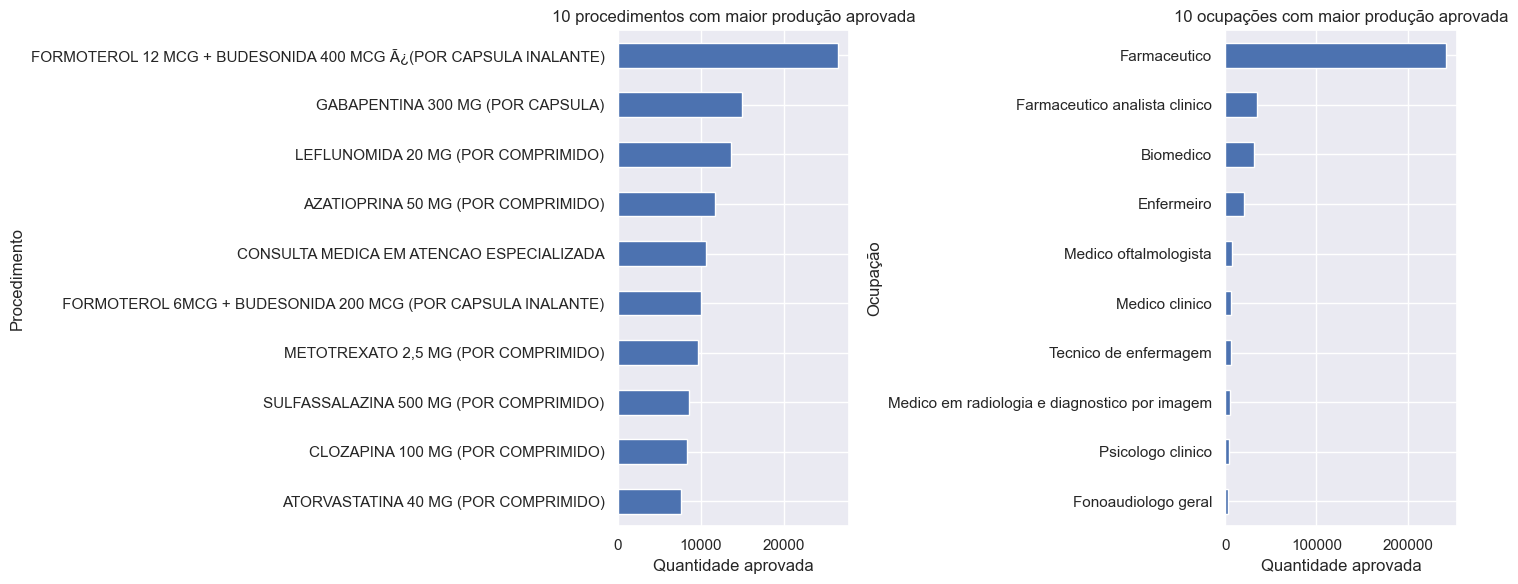

In [16]:
# Calcula a quantidade aprovada por procedimento.
procedimentos = tabela.groupby("Procedimento")["pa_qtdapr"].sum()

# Calcula a quantidade aprovada por ocupação profissional.
ocupacoes = tabela.groupby("Ocupacao")["pa_qtdapr"].sum()

# Seleciona os 10 maiores resultados.
top_procedimentos = procedimentos.nlargest(10).sort_values()
top_ocupacoes = ocupacoes.nlargest(10).sort_values()

# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: procedimentos com maior quantidade aprovada.
top_procedimentos.plot(
    kind="barh", 
    ax=axes[0]
)
axes[0].set_title("10 procedimentos com maior produção aprovada")
axes[0].set_xlabel("Quantidade aprovada")
axes[0].set_ylabel("Procedimento")

# Gráfico 2: ocupações com maior quantidade aprovada.
top_ocupacoes.plot(
    kind="barh", 
    ax=axes[1]
)
axes[1].set_title("10 ocupações com maior produção aprovada")
axes[1].set_xlabel("Quantidade aprovada")
axes[1].set_ylabel("Ocupação")

# Ajusta e exibe os gráficos.
plt.tight_layout()
plt.show()

## 12. Perfil demográfico - barras e histograma

**Pergunta:** como se distribuem os registros com informação disponível por sexo e idade?

- **Barras:** distribuição de frequências por categoria de sexo, preservando os códigos encontrados na base (sem pressupor que sejam apenas `M`/`F`).
- **Histograma:** distribuição de idades em intervalos (*bins*).

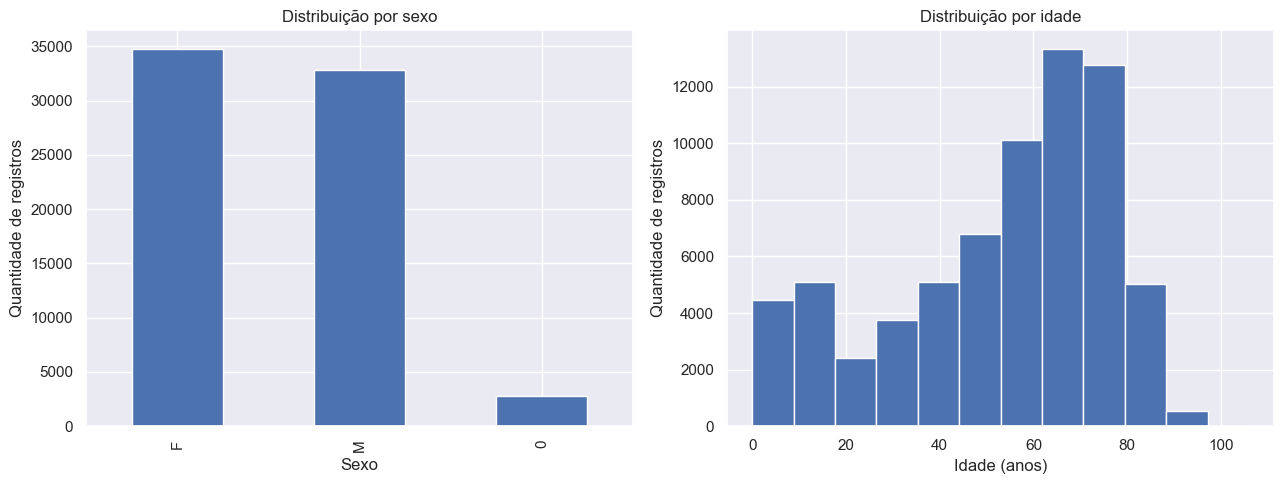

In [17]:
# Calcula a frequência dos registros por sexo.
sexo = tabela["pa_sexo"].value_counts()

# Converte as idades para valores numéricos.
idades = pd.to_numeric(tabela["pa_idade"])

# Considera somente idades entre 0 e 120 anos.
idades = idades[idades.between(0, 120)]

# Cria dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: distribuição por sexo.
sexo.plot(
    kind="bar", 
    ax=axes[0]
)
axes[0].set_title("Distribuição por sexo")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Quantidade de registros")

# Gráfico 2: distribuição das idades.
idades.plot(
    kind="hist", 
    bins=12, 
    ax=axes[1]
)
axes[1].set_title("Distribuição por idade")
axes[1].set_xlabel("Idade (anos)")
axes[1].set_ylabel("Quantidade de registros")

# Ajusta e exibe os gráficos.
plt.tight_layout()
plt.show()

## 13. Perfil demográfico - heatmap com Seaborn

`sns.heatmap()` destaca padrões em uma matriz. Aqui, a matriz relaciona **faixas etárias × códigos de sexo**, contando **registros** com informações disponíveis.

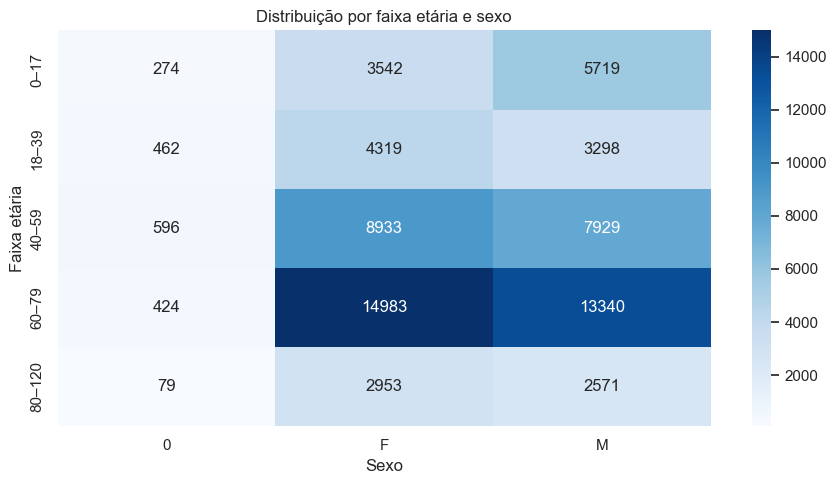

In [18]:
# Organiza as idades em faixas etárias.
faixas = pd.cut(
    idades,
    bins=[-1, 17, 39, 59, 79, 120],
    labels=["0–17", "18–39", "40–59", "60–79", "80–120"]
)

# Conta os registros por faixa etária e sexo.
matriz = pd.crosstab(faixas, tabela["pa_sexo"])

# Cria o mapa de calor.
plt.figure(figsize=(9, 5))

sns.heatmap(
    matriz, 
    annot=True, 
    fmt="d", 
    cmap="Blues"
)

plt.title("Distribuição por faixa etária e sexo")
plt.xlabel("Sexo")
plt.ylabel("Faixa etária")

plt.tight_layout()
plt.show()

## 14. Diagnósticos informados - gráfico de barras

**Pergunta:** quais diagnósticos aparecem mais frequentemente nos registros com CID10 informado?

A contagem utiliza **registros**, não pacientes distintos. 

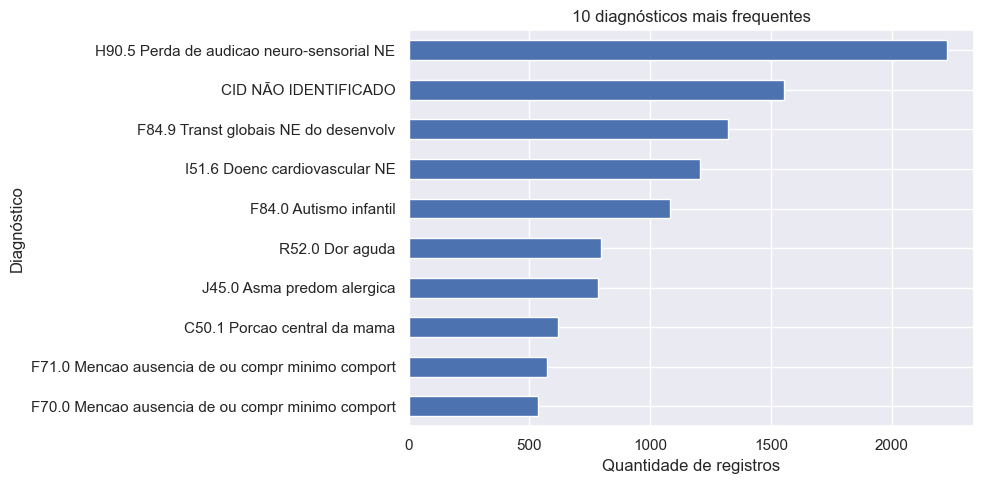

In [19]:
# Seleciona os registros que possuem CID principal informado.
dados = tabela[
    tabela["pa_cidpri"].notna() &
    ~tabela["pa_cidpri"].isin(["", "0000"])
]

# Conta os registros por diagnóstico.
diagnosticos = dados["Diagnostico"].value_counts()

# Seleciona os 10 diagnósticos mais frequentes.
top_diagnosticos = diagnosticos.head(10).sort_values()

# Cria o gráfico de barras horizontais.
top_diagnosticos.plot(
    kind="barh", 
    figsize=(10, 5)
)

plt.title("10 diagnósticos mais frequentes")
plt.xlabel("Quantidade de registros")
plt.ylabel("Diagnóstico")

plt.tight_layout()
plt.show()

## 15. Fluxos regionais - municípios informados nos registros

**Pergunta:** quais municípios aparecem no campo `MunicipioPaciente` e qual parcela dos registros informa município diferente de Ijuí?

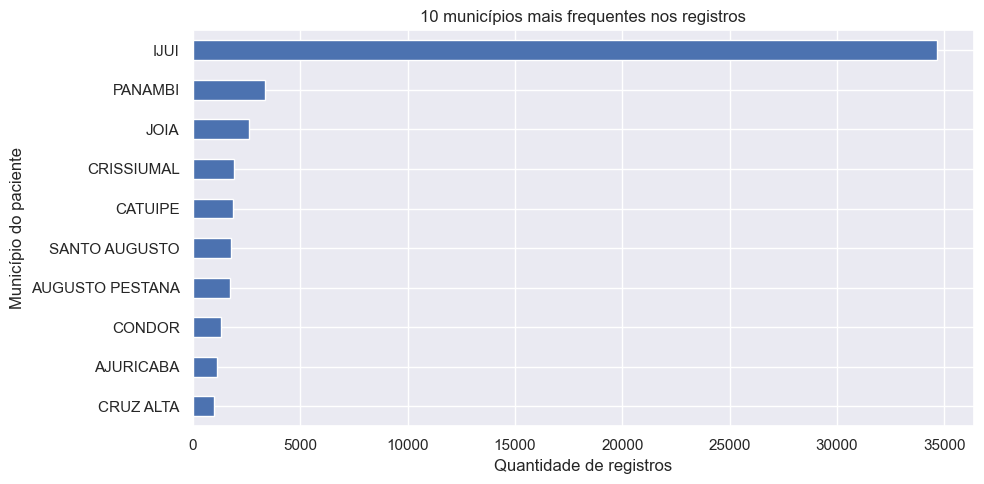

In [20]:
# Conta os registros por município do paciente.
municipios = tabela["MunicipioPaciente"].value_counts()

# Seleciona os 10 municípios com mais registros.
top_municipios = municipios.head(10).sort_values()

# Cria o gráfico de barras horizontais.
top_municipios.plot(
    kind="barh", 
    figsize=(10, 5)
)

plt.title("10 municípios mais frequentes nos registros")
plt.xlabel("Quantidade de registros")
plt.ylabel("Município do paciente")

plt.tight_layout()
plt.show()

## Comandos úteis no Pandas

| Comando | Aplicação |
|---|---|
| `pd.DataFrame()` | Carregar resultado da VIEW |
| `.shape`, `.dtypes`, `.head()`, `.tail()` | Exploração estrutural |
| `.loc[]`, `.iloc[]` | Seleção de linhas e colunas |
| `pd.to_numeric()` | Preparar variáveis numéricas |
| `.describe()`, `.median()`, `.value_counts()` | Estatística descritiva |
| `.isna()`, `.duplicated()`, `.dropna()` | Qualidade e limpeza (sem exclusão automática) |
| `.groupby().agg()` | Agregação por tempo, estabelecimento, procedimento e perfil |
| `.sort_values()`, `.head()` | Rankings |
| `.diff()`, `.pct_change()` | Variação temporal |
| `.str.contains()` | Triagem textual exploratória |
| `pd.cut()` | Construção de faixas etárias |

## Comandos úteis de visualização

| Comando | Aplicação |
|---|---|
| `fig, ax = plt.subplots()` | Criar figuras e eixos |
| `ax.bar()` / `ax.barh()` | Comparar estabelecimentos, procedimentos e municípios |
| `ax.plot()` | Representar séries mensais e indicadores financeiros |
| `ax.hist()` | Explorar a distribuição das idades |
| `sns.boxplot()` | Explorar a dispersão das quantidades por registro |
| `sns.heatmap()` | Representar frequências por idade e sexo |
| `plt.tight_layout()` / `plt.show()` | Organizar e apresentar figuras |

**Ordem de execução:** Etapa 2 completa → configuração de Matplotlib e Seaborn → gráficos e interpretações da Etapa 3.
